# M4: PD group comparison and per-participant session traces

`PLANScores.md` M4: `plotting.plot_subjects_fm100`/`plot_group_vs_subjects_fm100` cap out at `SUBJECT_COLORS` (4 subjects) -- too few to compare PD's 6 unique subjects individually. Two new functions instead:

- `plot_group_all_subjects_fm100` -- every matching subject's own profile (sessions averaged first) as its own colored line (`FULL_PALETTE`, one subject = one legend entry), plus the group mean in a heavier line on top.
- `plot_subjects_grid_fm100` -- one `plot_subject_fm100` panel per subject, that subject's own sessions overlaid (`SESSION_COLORS`), in a grid -- the session-level view, feasible here because PD is a small group.

In [1]:
import sys
sys.path.append('../scripts')

import loader
import plotting

df = loader.load_fm100_raw()
sub_ids = loader.subjects_in_group(df, group='PD')
sub_ids

['MET025', 'MET030', 'MET037', 'MET038', 'MET039', 'MET040']

## All PD participants: linear and radial

Each participant's own error profile (own sessions averaged) gets its own `FULL_PALETTE` color and legend entry; the group mean is the heavier, near-black line. `window=5` matches this project's established smoothing convention (`03_flagged_subjects.ipynb`); `show_cap_wheel=True` (radial) / `show_cap_colors=True` (linear) draw the colored cap reference, ring or x-axis dots.

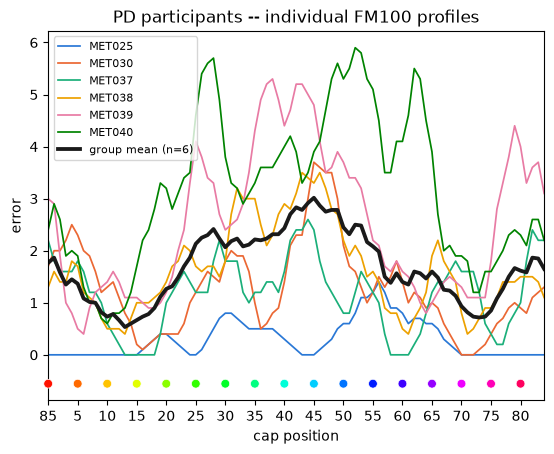

In [2]:
plotting.plot_group_all_subjects_fm100(df, group='PD', kind='linear', window=5, show_cap_colors=True);

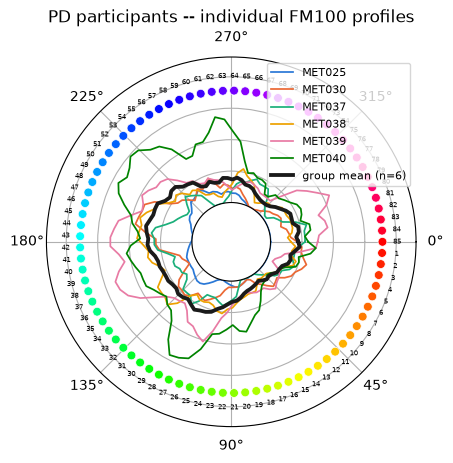

In [3]:
plotting.plot_group_all_subjects_fm100(df, group='PD', kind='radial', window=5, show_cap_wheel=True);

## Per-participant session traces

One panel per PD participant, that participant's own sessions overlaid -- feasible as a grid since the group is small (n=6). `share_ylim=True` (the default) puts every linear panel on the same y-range and every radial panel on the same r-range, so a bigger loop/peak means a bigger error, not a smaller per-subject autoscale.

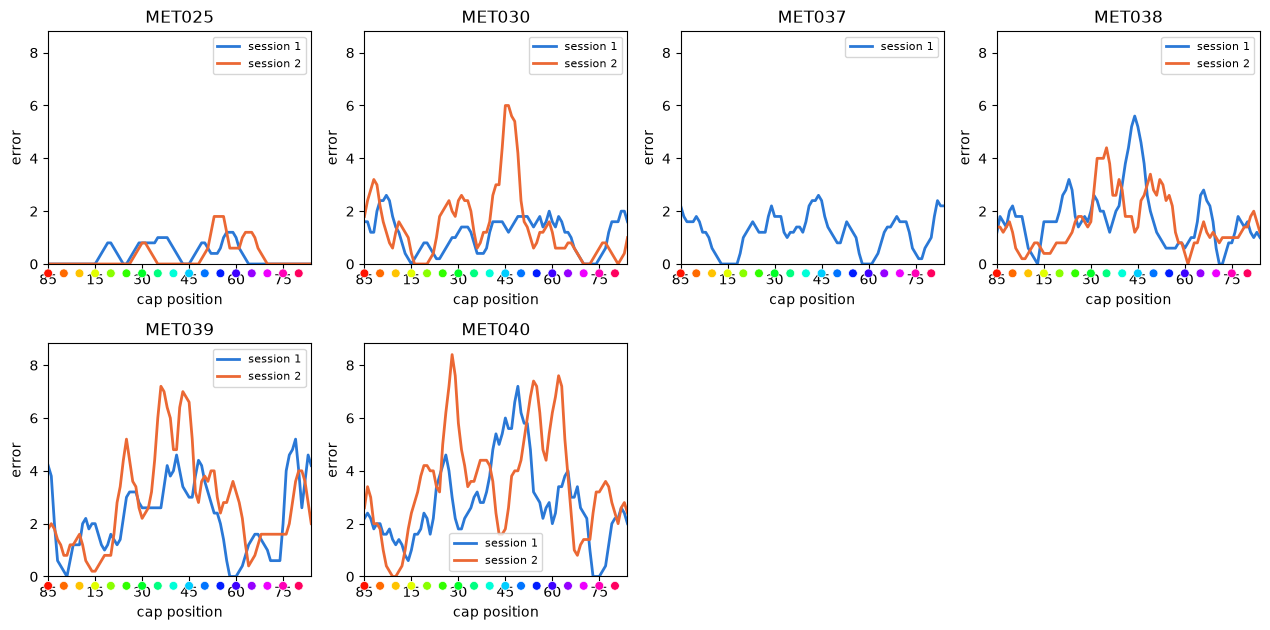

In [4]:
plotting.plot_subjects_grid_fm100(df, sub_ids, kind='linear', window=5, show_cap_colors=True);

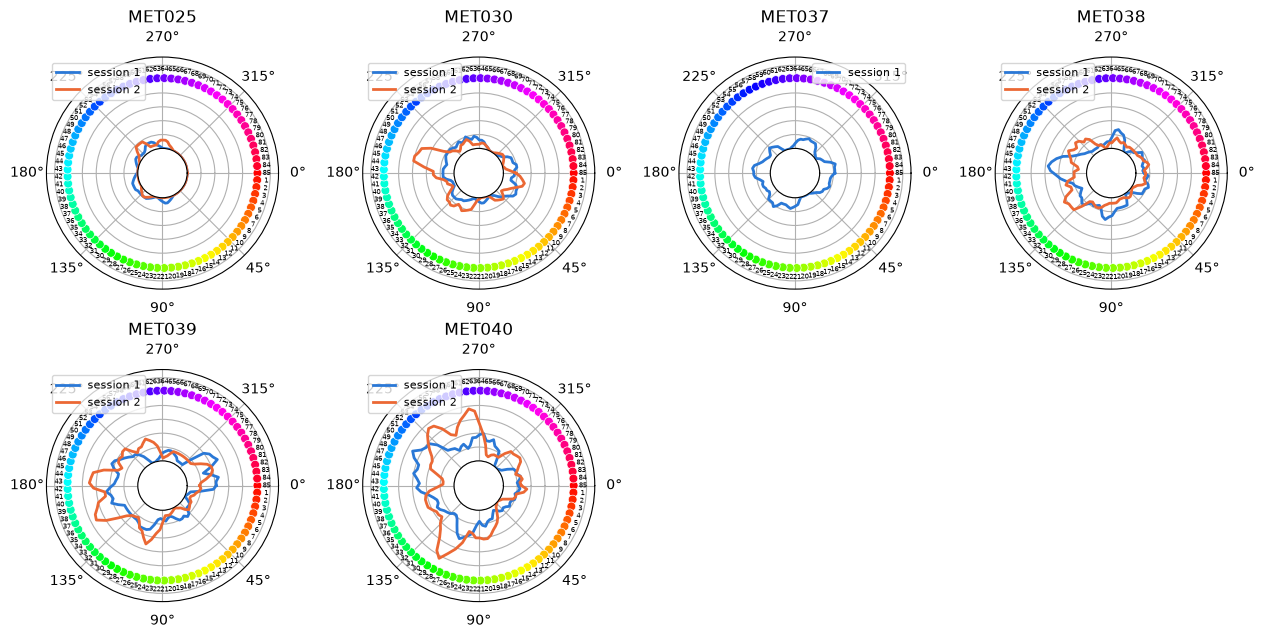

In [5]:
plotting.plot_subjects_grid_fm100(df, sub_ids, kind='radial', window=5, show_cap_wheel=True);